In [1]:
try:
    import google.colab
    print('Running on CoLab')
    #!pip install roboticstoolbox-python>=1.0.2
    !pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    !pip install spatialmath-python>=1.1.5
    !pip install bdsim
    !pip install --no-deps rvc3python
    COLAB = True
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

In [2]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
models_dir = os.path.join(rvc.__path__[0], 'models')
sys.path.append(models_dir)

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *

In [3]:
data = rtb_load_jsonfile("data/queensland.json")

{'places': {'Brisbane': {'lat': -27.4697707,
   'lon': 153.0251235,
   'utm': [1095.9145867144744, 6947.043658018596]},
  'Camooweal': {'lat': -19.920667,
   'lon': 138.1213324,
   'utm': [-432.103885525028, 7772.551709375787]},
  'Mount Isa': {'lat': -20.7255748,
   'lon': 139.4927085,
   'utm': [-283.3325926415254, 7689.989162769402]},
  'Cloncurry': {'lat': -20.7063927,
   'lon': 140.5093258,
   'utm': [-176.971789275437, 7696.747610678524]},
  'Hughenden': {'lat': -20.85,
   'lon': 144.2,
   'utm': [208.62239381884905, 7691.917660932694]},
  'Charters Towers': {'lat': -20.0769637,
   'lon': 146.2601362,
   'utm': [422.6424087047931, 7779.8303889114595]},
  'Townsville': {'lat': -19.2589635,
   'lon': 146.8169483,
   'utm': [480.763802457357, 7870.508270739987]},
  'Boulia': {'lat': -22.911306,
   'lon': 139.910444,
   'utm': [-228.32608073938195, 7448.695027567425]},
  'Winton': {'lat': -22.3913,
   'lon': 143.0381,
   'utm': [91.94835708401399, 7518.4805284370905]},
  'Bedourie': 

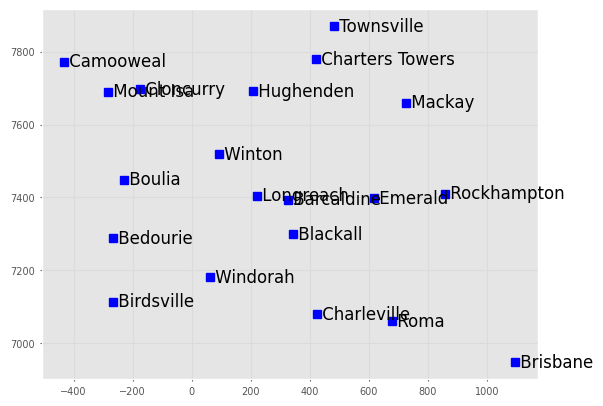

In [4]:
for name, info in data["places"].items():
    plot_point(info["utm"], text=name)

In [6]:
data["routes"][0]

{'start': 'Camooweal', 'end': 'Mount Isa', 'distance': 188, 'speed': 100}

In [7]:
import pgraph

g = pgraph.UGraph() # create empty undirected graph

for name, info in data["places"].items():
    g.add_vertex(name=name, coord=info["utm"])  # add a place
    
for route in data["routes"]:
    g.add_edge(route["start"], route["end"],
               cost=route["distance"])  # add a route

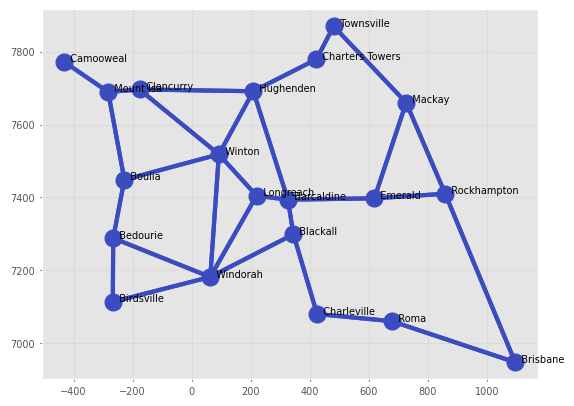

In [8]:
g.plot()

In [9]:
g.n

20

In [10]:
g.ne

29

In [11]:
g["Brisbane"]

UVertex[Brisbane, coord=(1096, 6947)]

In [13]:
g["Brisbane"].neighbors()

[UVertex[Rockhampton, coord=(858.9, 7410)], UVertex[Roma, coord=(677.7, 7060)]]

In [14]:
g["Brisbane"].degree

2

In [15]:
g.average_degree()

2.9

In [16]:
g.nc

1

In [17]:
edges = g["Brisbane"].edges()

[Edge{[Rockhampton] -- [Brisbane], cost=682},
 Edge{[Brisbane] -- [Roma], cost=482}]

In [19]:
edges[0].endpoints

[UVertex[Rockhampton, coord=(858.9, 7410)],
 UVertex[Brisbane, coord=(1096, 6947)]]

In [20]:
path, length = g.path_BFS("Hughenden", "Brisbane")
length

1759

In [21]:
", ".join([p.name for p in path])

'Hughenden, Barcaldine, Emerald, Rockhampton, Brisbane'

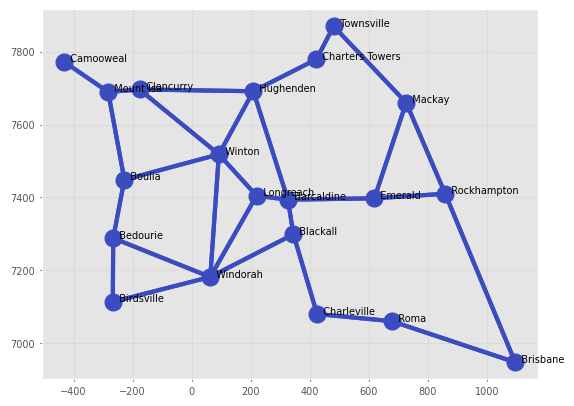

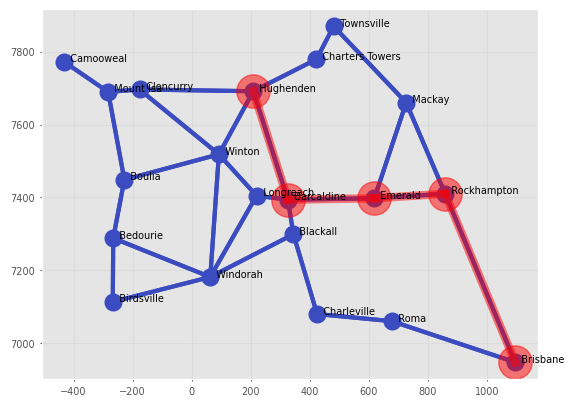

In [ ]:
fig, ax = plt.subplots()
g.plot(ax=ax, block=False)
plt.sca(ax)  # Make this the active plotting area
g.highlight_path(path, block=False, color="red")
plt.show()

In [26]:
g.path_BFS("Hughenden", "Brisbane", verbose=True)


FRONTIER: Hughenden
EXPLORED: 
   expand Hughenden
      add Cloncurry to the frontier
      add Charters Towers to the frontier
      add Barcaldine to the frontier
      add Winton to the frontier
     move Hughenden to the explored list

FRONTIER: Cloncurry, Charters Towers, Barcaldine, Winton
EXPLORED: Hughenden
   expand Cloncurry
      add Mount Isa to the frontier
     move Cloncurry to the explored list

FRONTIER: Charters Towers, Barcaldine, Winton, Mount Isa
EXPLORED: Hughenden, Cloncurry
   expand Charters Towers
      add Townsville to the frontier
     move Charters Towers to the explored list

FRONTIER: Barcaldine, Winton, Mount Isa, Townsville
EXPLORED: Hughenden, Cloncurry, Charters Towers
   expand Barcaldine
      add Blackall to the frontier
      add Emerald to the frontier
      add Longreach to the frontier
     move Barcaldine to the explored list

FRONTIER: Winton, Mount Isa, Townsville, Blackall, Emerald, Longreach
EXPLORED: Hughenden, Cloncurry, Charters Towe

([UVertex[Hughenden, coord=(208.6, 7692)],
  UVertex[Barcaldine, coord=(325.8, 7394)],
  UVertex[Emerald, coord=(618.9, 7398)],
  UVertex[Rockhampton, coord=(858.9, 7410)],
  UVertex[Brisbane, coord=(1096, 6947)]],
 1759)

In [28]:
path, length, parents = g.path_UCS("Hughenden", "Brisbane")
length

1659

In [29]:
", ".join([p.name for p in path])

'Hughenden, Barcaldine, Blackall, Charleville, Roma, Brisbane'

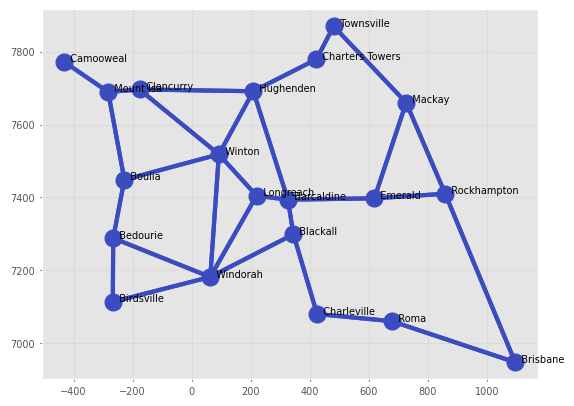

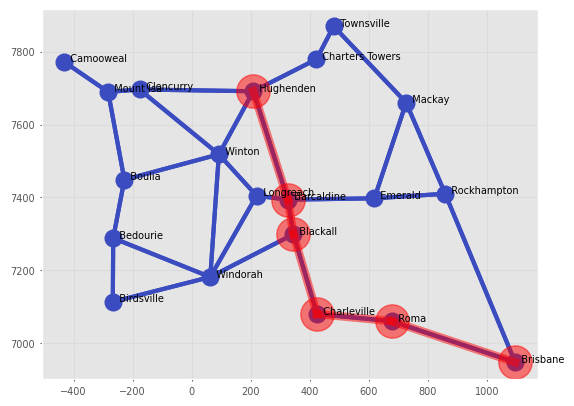

In [30]:
fig, ax = plt.subplots()
g.plot(ax=ax, block=False)
plt.sca(ax)  # Make this the active plotting area
g.highlight_path(path, block=False, color="red")
plt.show()

In [32]:
parents["Winton"]

'Hughenden'

In [39]:
tree = pgraph.DGraph.Dict(parents)
tree.showgraph()

In [40]:
g.path_UCS("Hughenden", "Brisbane", verbose=True)


FRONTIER: Hughenden(0)
EXPLORED: 
   expand Hughenden
      add Cloncurry to the frontier
      add Charters Towers to the frontier
      add Barcaldine to the frontier
      add Winton to the frontier
     move Hughenden to the explored list

FRONTIER: Cloncurry(401), Charters Towers(248), Barcaldine(500), Winton(216)
EXPLORED: Hughenden
   expand Winton
      add Longreach to the frontier
      add Boulia to the frontier
      add Windorah to the frontier
     move Winton to the explored list

FRONTIER: Cloncurry(401), Charters Towers(248), Barcaldine(500), Longreach(396), Boulia(579), Windorah(703)
EXPLORED: Hughenden, Winton
   expand Charters Towers
      add Townsville to the frontier
     move Charters Towers to the explored list

FRONTIER: Cloncurry(401), Barcaldine(500), Longreach(396), Boulia(579), Windorah(703), Townsville(383)
EXPLORED: Hughenden, Winton, Charters Towers
   expand Townsville
      add Mackay to the frontier
     move Townsville to the explored list

FRONTI

([UVertex[Hughenden, coord=(208.6, 7692)],
  UVertex[Barcaldine, coord=(325.8, 7394)],
  UVertex[Blackall, coord=(344.5, 7299)],
  UVertex[Charleville, coord=(424.7, 7080)],
  UVertex[Roma, coord=(677.7, 7060)],
  UVertex[Brisbane, coord=(1096, 6947)]],
 1659,
 {'Cloncurry': 'Hughenden',
  'Charters Towers': 'Hughenden',
  'Barcaldine': 'Hughenden',
  'Winton': 'Hughenden',
  'Longreach': 'Winton',
  'Boulia': 'Winton',
  'Windorah': 'Winton',
  'Townsville': 'Charters Towers',
  'Mackay': 'Townsville',
  'Mount Isa': 'Cloncurry',
  'Blackall': 'Barcaldine',
  'Emerald': 'Barcaldine',
  'Camooweal': 'Mount Isa',
  'Bedourie': 'Boulia',
  'Charleville': 'Blackall',
  'Birdsville': 'Bedourie',
  'Rockhampton': 'Emerald',
  'Roma': 'Charleville',
  'Brisbane': 'Roma'})

In [41]:
g["Bedourie"].edgeto(g["Birdsville"]).cost

193

In [42]:
path, length, parents = g.path_Astar("Hughenden", "Brisbane", summary=True)

12 vertices explored, 3 remaining on the frontier


In [43]:
length

1659

In [44]:
", ".join([p.name for p in path])

'Hughenden, Barcaldine, Blackall, Charleville, Roma, Brisbane'

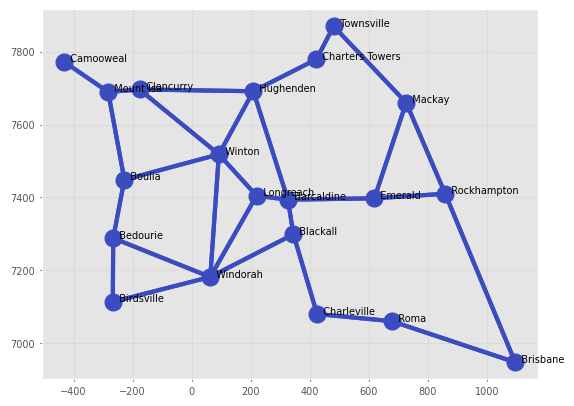

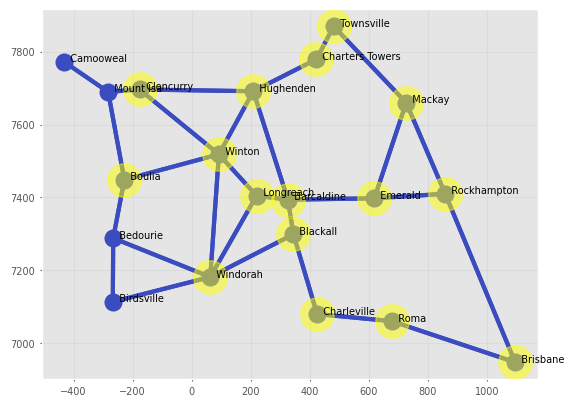

In [51]:
visited = set(parents.keys()) | set(parents.values())

fig, ax = plt.subplots()

g.plot(ax=ax, block=False)

# Convert city names to actual graph vertex objects
vertices = [g[name] for name in visited if name in g._vertexdict]
plt.sca(ax)
g.highlight_vertex(vertices, color="yellow")

plt.show()

### Minimum-Time Path Planning

In [52]:
g = pgraph.UGraph()
for name, info in data["places"].items():
    g.add_vertex(name=name, coord=info["utm"])
for route in data["routes"]:
    g.add_edge(route["start"], route["end"], cost=route["distance"] / route["speed"])

In [53]:
g.heuristic = lambda x: np.linalg.norm(x) / 100

In [55]:
path, time, _ = g.path_Astar("Hughenden", "Brisbane")
time

16.610000000000003

In [56]:
", ".join([p.name for p in path])

'Hughenden, Winton, Longreach, Barcaldine, Blackall, Charleville, Roma, Brisbane'